<a href="https://colab.research.google.com/github/vheyue/credit-risk-prediction/blob/main/notebooks/credit_risk_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Descargar el dataset
german_credit = fetch_ucirepo(id=144)

# variables
X = german_credit.data.features
y = german_credit.data.targets

# crear DataFrame
df = pd.concat([X,y], axis=1)

# mostrar primeras filas
df.head()

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
# dimensiones
print(df.shape)

# info columnas
df.info()

# nulos
print(df.isnull().sum())

(1000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribute18  1000 non-null   int64 
 18  Attribute19  1000 non-null   object
 19  Attribute20  1000

In [4]:
# veamos el porcentaje
df["class"].value_counts(normalize=True)*100

,proportion
class,
1,70.0
2,30.0


In [5]:
# describir el dataset
df.describe()

,Attribute2,Attribute5,Attribute8,Attribute11,Attribute13,Attribute16,Attribute18,class
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


In [6]:
# modificar nombre
df = df.rename(columns={"Attribute13":"edad"})

# describir columna
df["edad"].describe()

,edad
count,1000.000000
mean,35.546000
std,11.375469
min,19.000000
25%,27.000000
50%,33.000000
75%,42.000000
max,75.000000


In [7]:
# agrupar por clase
df.groupby("class")["edad"].mean()

,edad
class,
1,36.224286
2,33.963333


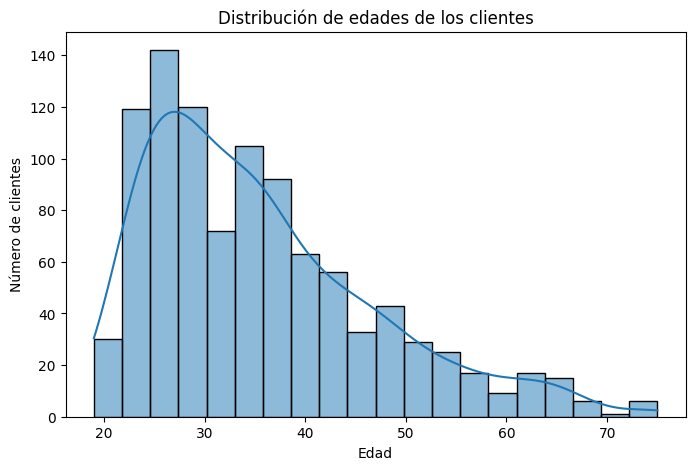

In [8]:
# visualizar número de clientes x edad
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="edad",
    bins=20,
    kde=True
)

plt.title("Distribución de edades de los clientes")
plt.xlabel("Edad")
plt.ylabel("Número de clientes")

plt.show()

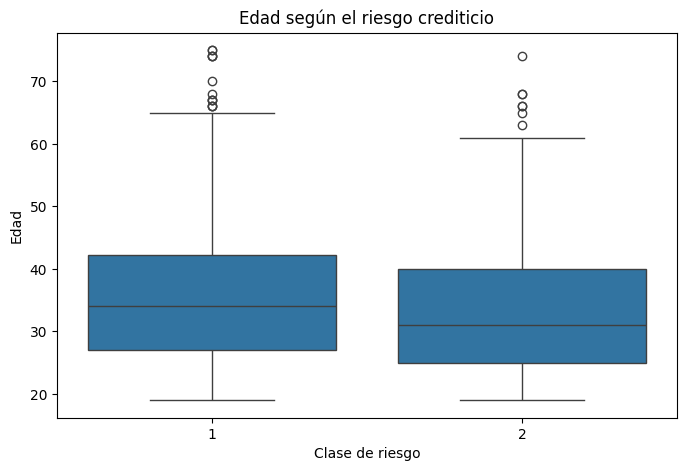

In [9]:
# visualizar edad según riesgo

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="class",
    y="edad"
)

plt.title("Edad según el riesgo crediticio")
plt.xlabel("Clase de riesgo")
plt.ylabel("Edad")

plt.show()

In [10]:
# modificar nombres y describe
df = df.rename(columns={"Attribute2":"duracion", "Attribute5":"importe"})
df[["duracion","importe"]].describe()

,duracion,importe
count,1000.000000,1000.000000
mean,20.903000,3271.258000
std,12.058814,2822.736876
min,4.000000,250.000000
25%,12.000000,1365.500000
50%,18.000000,2319.500000
75%,24.000000,3972.250000
max,72.000000,18424.000000


In [11]:
# importe por clase
df.groupby("class")["importe"].mean()

,importe
class,
1,2985.457143
2,3938.126667


In [12]:
# duración por clase
df.groupby("class")["duracion"].mean()

,duracion
class,
1,19.207143
2,24.860000


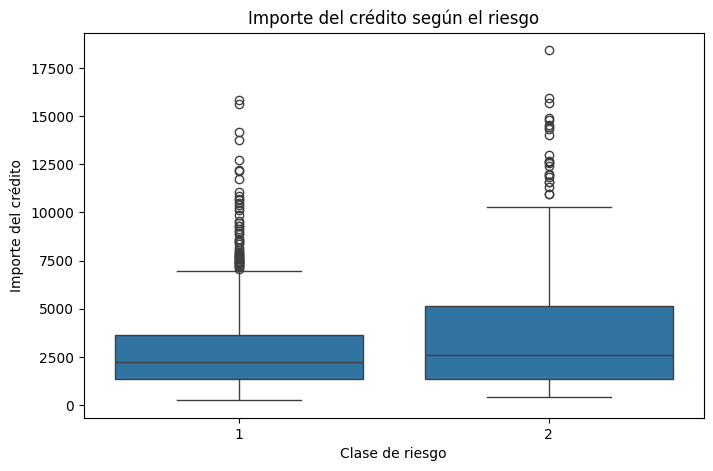

In [13]:
# visualizar importe por riesgo
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="class",
    y="importe"
)

plt.title("Importe del crédito según el riesgo")
plt.xlabel("Clase de riesgo")
plt.ylabel("Importe del crédito")

plt.show()


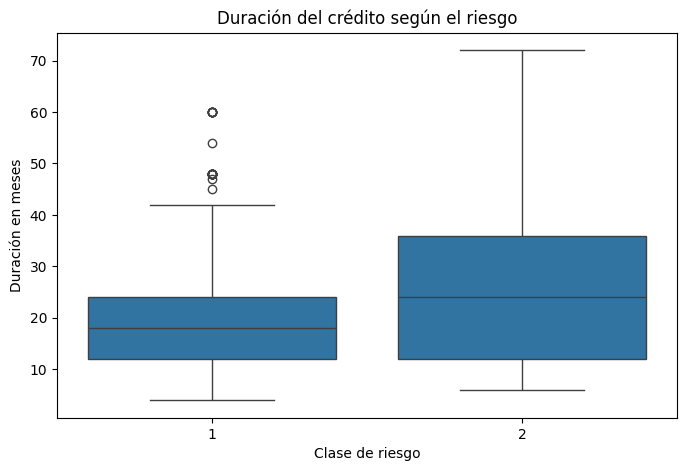

In [14]:
# visualizar duración según riesgo
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="class",
    y="duracion"
)

plt.title("Duración del crédito según el riesgo")
plt.xlabel("Clase de riesgo")
plt.ylabel("Duración en meses")

plt.show()


In [15]:
# estudiar correlaciones
variables = df[["edad","importe","duracion"]]
correlaciones = variables.corr()
print(correlaciones)

              edad   importe  duracion
edad      1.000000  0.032716 -0.036136
importe   0.032716  1.000000  0.624984
duracion -0.036136  0.624984  1.000000


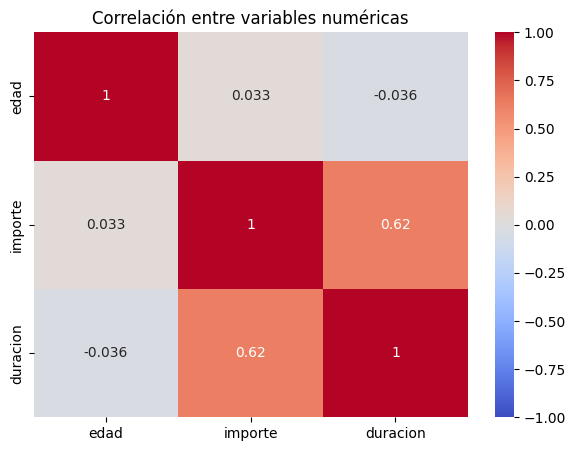

In [16]:
# visualizar correlaciones
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre variables numéricas")

plt.show()

In [17]:
# definimos las variables predictoras y objetivo

X = df.drop(columns=["class"])
y = df["class"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print(X.dtypes.value_counts())
print(X.select_dtypes(include=["object","category"]).columns)

Dimensiones de X: (1000, 20)
Dimensiones de y: (1000,)
object    13
int64      7
Name: count, dtype: int64
Index(['Attribute1', 'Attribute3', 'Attribute4', 'Attribute6', 'Attribute7',
       'Attribute9', 'Attribute10', 'Attribute12', 'Attribute14',
       'Attribute15', 'Attribute17', 'Attribute19', 'Attribute20'],
      dtype='object')


In [18]:
# pasamos variables cualitativas a 0,1
X_encoded = pd.get_dummies(X, dtype=int)

print("Antes:", X.shape)
print("Después:", X_encoded.shape)
X_encoded.head()

Antes: (1000, 20)
Después: (1000, 61)


,duracion,importe,Attribute8,Attribute11,edad,Attribute16,Attribute18,Attribute1_A11,Attribute1_A12,Attribute1_A13,...,Attribute15_A152,Attribute15_A153,Attribute17_A171,Attribute17_A172,Attribute17_A173,Attribute17_A174,Attribute19_A191,Attribute19_A192,Attribute20_A201,Attribute20_A202
0,6,1169,4,4,67,2,1,1,0,0,...,1,0,0,0,1,0,0,1,1,0
1,48,5951,2,2,22,1,1,0,1,0,...,1,0,0,0,1,0,1,0,1,0
2,12,2096,2,3,49,1,2,0,0,0,...,1,0,0,1,0,0,1,0,1,0
3,42,7882,2,4,45,1,2,1,0,0,...,0,1,0,0,1,0,1,0,1,0
4,24,4870,3,4,53,2,2,1,0,0,...,0,1,0,0,1,0,1,0,1,0


In [19]:
# separamos las variables

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split (
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y # para mantener las proporciones
)

In [20]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 20)
X_test: (200, 20)
y_train: (800,)
y_test: (200,)


In [21]:
print("Entrenamiento:")
print(y_train.value_counts(normalize=True))

print("Prueba:")
print(y_test.value_counts(normalize=True))

Entrenamiento:
class
1    0.7
2    0.3
Name: proportion, dtype: float64
Prueba:
class
1    0.7
2    0.3
Name: proportion, dtype: float64


In [22]:
# preprocesameinto de datos

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

columnas_categoricas = X.select_dtypes(
    include = ["object", "category"]
).columns

columnas_numericas = X.select_dtypes(
    include = ["int64","float64"]
).columns

preprocesador = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas),
        ("numericas", StandardScaler(), columnas_numericas)
    ]
)

In [23]:
# creación, entrenamiento y predicción del modelo

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("classificador", LogisticRegression(max_iter=1000))
    ]
)
modelo.fit(X_train, y_train) # entrenamos modelo
y_pred = modelo.predict(X_test) # predecir con el test

In [24]:
print(y_pred[:10])

[1 1 2 1 1 1 1 1 1 1]


In [25]:
# métricas

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label=2))
print("Recall:", recall_score(y_test, y_pred, pos_label=2))
print("F1 score:", f1_score(y_test, y_pred, pos_label=2))

matriz = confusion_matrix (
    y_test,
    y_pred,
    labels=[1,2]
)
print(matriz)


Accuracy: 0.78
Precision: 0.6666666666666666
Recall: 0.5333333333333333
F1 score: 0.5925925925925926
[[124  16]
 [ 28  32]]


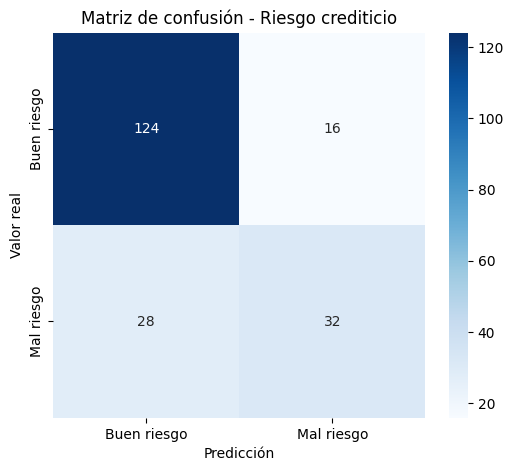

In [26]:
# visualizar matriz de confusión

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Buen riesgo", "Mal riesgo"],
    yticklabels=["Buen riesgo", "Mal riesgo"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Riesgo crediticio")

plt.show()

In [27]:
# vemos las probabilidades

probabilidades = modelo.predict_proba(X_test)

print(modelo.classes_)
print(probabilidades[:5])

[1 2]
[[0.77319206 0.22680794]
 [0.89854174 0.10145826]
 [0.38123154 0.61876846]
 [0.50664292 0.49335708]
 [0.84983813 0.15016187]]


In [28]:
# modificamos umbral y vemos métricas
prob_mal_riesgo = probabilidades[:,1]
y_pred_030 = [
     2 if prob >= 0.3 else 1
    for prob in prob_mal_riesgo

]

print("Precision:", precision_score(
    y_test, y_pred_030, pos_label=2
))

print("Recall:", recall_score(
    y_test, y_pred_030, pos_label=2
))

print("F1-score:", f1_score(
    y_test, y_pred_030, pos_label=2
))

print("Matriz de confusión:")
print(confusion_matrix(
    y_test, y_pred_030, labels=[1, 2]
))

Precision: 0.5632183908045977
Recall: 0.8166666666666667
F1-score: 0.6666666666666666
Matriz de confusión:
[[102  38]
 [ 11  49]]


In [29]:
# Coste de errores

coste_fn = 5000
coste_fp = 500

matriz_050 = confusion_matrix(
    y_test, y_pred, labels=[1, 2]
)

matriz_030 = confusion_matrix(
    y_test, y_pred_030, labels=[1, 2]
)

fn_050 = matriz_050[1, 0]
fp_050 = matriz_050[0, 1]

fn_030 = matriz_030[1, 0]
fp_030 = matriz_030[0, 1]

coste_050 = fn_050 * coste_fn + fp_050 * coste_fp
coste_030 = fn_030 * coste_fn + fp_030 * coste_fp

print("Coste umbral 0.50:", coste_050)
print("Coste umbral 0.30:", coste_030)

Coste umbral 0.50: 148000
Coste umbral 0.30: 74000


In [30]:
# Resumen de los resultados

resultados = pd.DataFrame({
    "Umbral": [0.50, 0.30],
    "Accuracy": [0.78, 0.755],
    "Precision": [0.6667, 0.5632],
    "Recall": [0.5333, 0.8167],
    "F1-score": [0.5926, 0.6667],
    "Coste": [148000, 74000]
})

resultados

,Umbral,Accuracy,Precision,Recall,F1-score,Coste
0,0.5,0.780,0.6667,0.5333,0.5926,148000
1,0.3,0.755,0.5632,0.8167,0.6667,74000


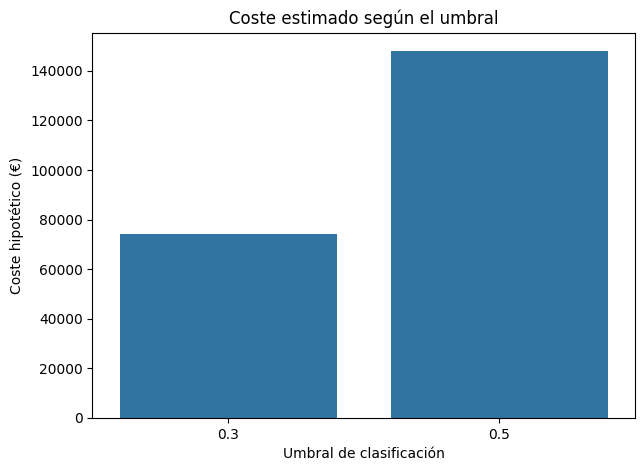

In [31]:
# Gráfico de resultados

plt.figure(figsize=(7, 5))

sns.barplot(
    data=resultados,
    x="Umbral",
    y="Coste"
)

plt.title("Coste estimado según el umbral")
plt.xlabel("Umbral de clasificación")
plt.ylabel("Coste hipotético (€)")

plt.show()